In [2]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sympy import true
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

# Enable Apple Silicon GPU acceleration
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [3]:
# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Transforms: Standardize size, augment training images, normalize to ImageNet stats
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load full dataset
full_dataset = datasets.ImageFolder(root=str(DATA_DIR))
classes = full_dataset.classes
print(f"Classes: {classes}")

# Split into 70% Train, 15% Validation, 15% Test
total_count = len(full_dataset)
train_count = int(0.70 * total_count)
val_count = int(0.15 * total_count)
test_count = total_count - train_count - val_count

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_count, val_count, test_count],
    generator=torch.Generator().manual_seed(42)
)

# Apply transforms to subsets
train_subset.dataset.transform = train_transforms
val_subset.dataset.transform = val_test_transforms
test_subset.dataset.transform = val_test_transforms

# DataLoaders
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_subset, batch_size=32, shuffle=True, num_workers=2)

print(f"Samples -> Train: {len(train_subset)}, Val: {len(val_subset)}, Test: {len(test_subset)}")

Classes: ['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable']
Samples -> Train: 2041, Val: 437, Test: 439


In [4]:
# Load pre-trained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Step 1: Freeze all pre-trained convolutional feature extractor layers
for param in model.parameters():
    param.requires_grad = False

# Step 2: Replace final classification head with Dropout + Linear layer
num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(num_features, len(classes))
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
# Only pass parameters that require gradients (the new head)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001, weight_decay=1e-4)

In [5]:
num_epochs = 10
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)

    print(f"Epoch {epoch+1}: Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

Epoch 1/10 [Train]:   0%|          | 0/64 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 1/10 [Train]:  36%|███▌      | 23/64 [00:05<00:06,  6.59it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 1/10 [Train]: 100%|██████████| 64/64 [00:19<00:00,  3.21it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes 

Epoch 1: Train Acc: 0.4434 | Val Acc: 0.5767


Epoch 2/10 [Train]:   0%|          | 0/64 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 2/10 [Train]:   9%|▉         | 6/64 [00:02<00:15,  3.65it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 2/10 [Train]: 100%|██████████| 64/64 [00:19<00:00,  3.27it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes s

Epoch 2: Train Acc: 0.6022 | Val Acc: 0.6293


Epoch 3/10 [Train]:   2%|▏         | 1/64 [00:01<01:52,  1.79s/it]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 3/10 [Train]: 100%|██████████| 64/64 [00:19<00:00,  3.30it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/

...

Epoch 8: Train Acc: 0.6913 | Val Acc: 0.6659


Epoch 9/10 [Train]:   0%|          | 0/64 [00:00<?, ?it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 9/10 [Train]:   2%|▏         | 1/64 [00:01<01:52,  1.79s/it]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 9/10 [Train]: 100%|██████████| 64/64 [00:19<00:00,  3.21it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes s

Epoch 9: Train Acc: 0.6840 | Val Acc: 0.6705


Epoch 10/10 [Train]:  12%|█▎        | 8/64 [00:02<00:11,  4.67it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 10/10 [Train]:  81%|████████▏ | 52/64 [00:08<00:01,  8.45it/s]/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Epoch 10/10 [Train]: 100%|██████████| 64/64 [00:19<00:00,  3.29it/s]
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expresse

Epoch 10: Train Acc: 0.7011 | Val Acc: 0.6842


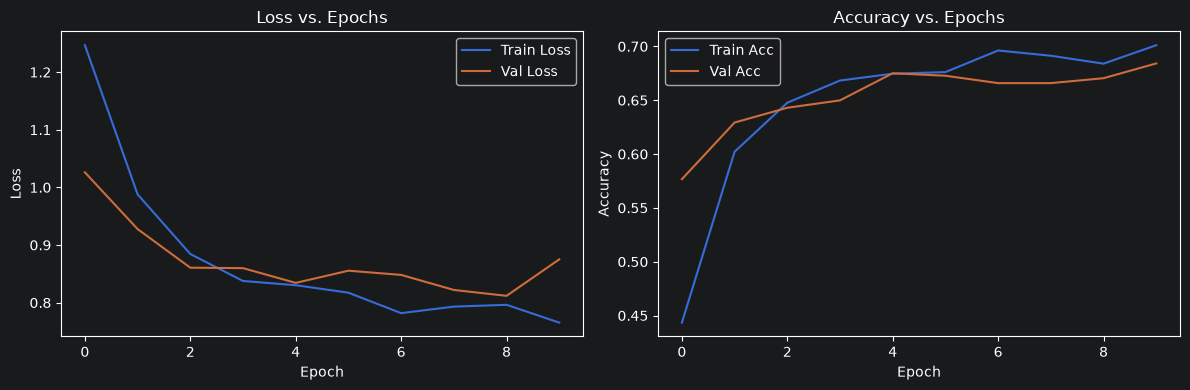

In [6]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.title("Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.title("Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



--- Deep Transfer Learning (ResNet-18) Performance ---
                precision    recall  f1-score   support

     Hazardous       0.67      0.88      0.76       163
Non-Recyclable       0.78      0.55      0.65        91
       Organic       0.84      0.73      0.78       107
    Recyclable       0.67      0.58      0.62        78

      accuracy                           0.72       439
     macro avg       0.74      0.68      0.70       439
  weighted avg       0.73      0.72      0.72       439



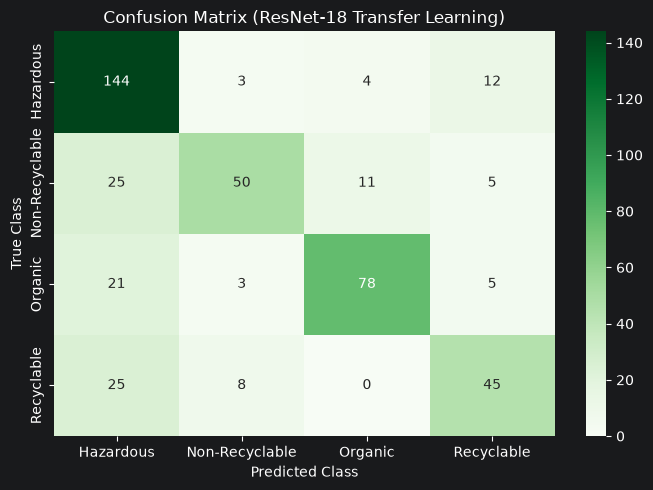

In [7]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n--- Deep Transfer Learning (ResNet-18) Performance ---")
print(classification_report(all_labels, all_preds, target_names=classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (ResNet-18 Transfer Learning)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

/Users/shaurya3006/PycharmProjects/Waste Classification/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


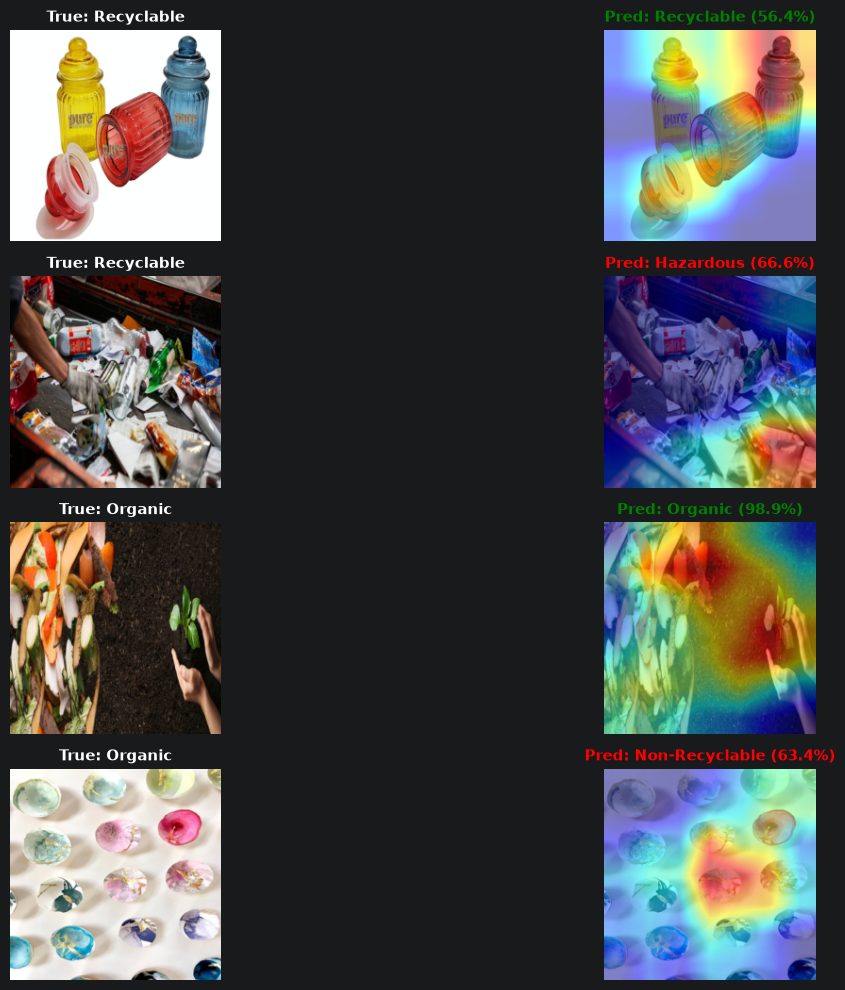

In [10]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

class GradCAM:
    """
    Computes Grad-CAM heatmaps on-demand and automatically removes
    hooks so standard model inference is never disrupted.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Ensure target layer can compute gradients for visualization
        for param in self.target_layer.parameters():
            param.requires_grad = True

    def generate_cam(self, input_tensor, class_idx=None):
        self.model.eval()

        # 1. Attach temporary hooks
        def _forward_hook(module, inp, out):
            self.activations = out.detach()

        def _backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        h_fwd = self.target_layer.register_forward_hook(_forward_hook)
        h_bwd = self.target_layer.register_full_backward_hook(_backward_hook)

        try:
            # 2. Forward pass with gradients enabled for CAM
            with torch.enable_grad():
                output = self.model(input_tensor)
                if class_idx is None:
                    class_idx = torch.argmax(output, dim=1).item()

                # 3. Backward pass for target class score
                self.model.zero_grad()
                target_score = output[0, class_idx]
                target_score.backward()

            # 4. Global Average Pooling over spatial dims
            weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)

            # 5. Weighted combination of activation maps
            cam = torch.sum(weights * self.activations, dim=1).squeeze()
            cam = F.relu(cam)  # Discard negative contributions

            # 6. Normalize between 0 and 1
            cam = cam - cam.min()
            if cam.max() > 0:
                cam = cam / cam.max()

            return cam.cpu().numpy(), class_idx, F.softmax(output, dim=1)[0, class_idx].item()

        finally:
            # 7. ALWAYS remove hooks so subsequent code runs without errors
            h_fwd.remove()
            h_bwd.remove()

def overlay_heatmap(rgb_img, cam_mask, alpha=0.5):
    heatmap = cv2.resize(cam_mask, (rgb_img.shape[1], rgb_img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap_colored = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    blended = np.float32(heatmap_colored) * alpha + np.float32(rgb_img) * (1 - alpha)
    blended = np.uint8(np.clip(blended, 0, 255))
    return heatmap_colored, blended

# --- Demonstrate Grad-CAM on 4 Test Samples ---
grad_cam = GradCAM(model=model, target_layer=model.layer4)
images_batch, labels_batch = next(iter(test_loader))

plt.figure(figsize=(16, 10))
num_display = min(4, len(images_batch))

for i in range(num_display):
    input_tensor = images_batch[i:i+1].to(device)
    true_label = classes[labels_batch[i].item()]

    cam_mask, pred_idx, confidence = grad_cam.generate_cam(input_tensor)
    pred_label = classes[pred_idx]

    inv_img = images_batch[i].cpu().permute(1, 2, 0).numpy()
    inv_img = inv_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    inv_img = np.uint8(np.clip(inv_img * 255, 0, 255))

    _, blended_img = overlay_heatmap(inv_img, cam_mask)

    plt.subplot(num_display, 2, 2 * i + 1)
    plt.imshow(inv_img)
    plt.title(f"True: {true_label}", fontsize=11, fontweight="bold")
    plt.axis("off")

    plt.subplot(num_display, 2, 2 * i + 2)
    plt.imshow(blended_img)
    color = "green" if pred_label == true_label else "red"
    plt.title(f"Pred: {pred_label} ({confidence * 100:.1f}%)", fontsize=11, fontweight="bold", color=color)
    plt.axis("off")

plt.tight_layout()
plt.show()

Evaluating: /Users/shaurya3006/PycharmProjects/Waste Classification/data/raw/Recyclable/Recyclable/cans_all_type/imgbin-beer-recycling-bottle-beverage-can-waste-container-n16Eb9uEgizMUQNdZ2pyKAidT.jpg


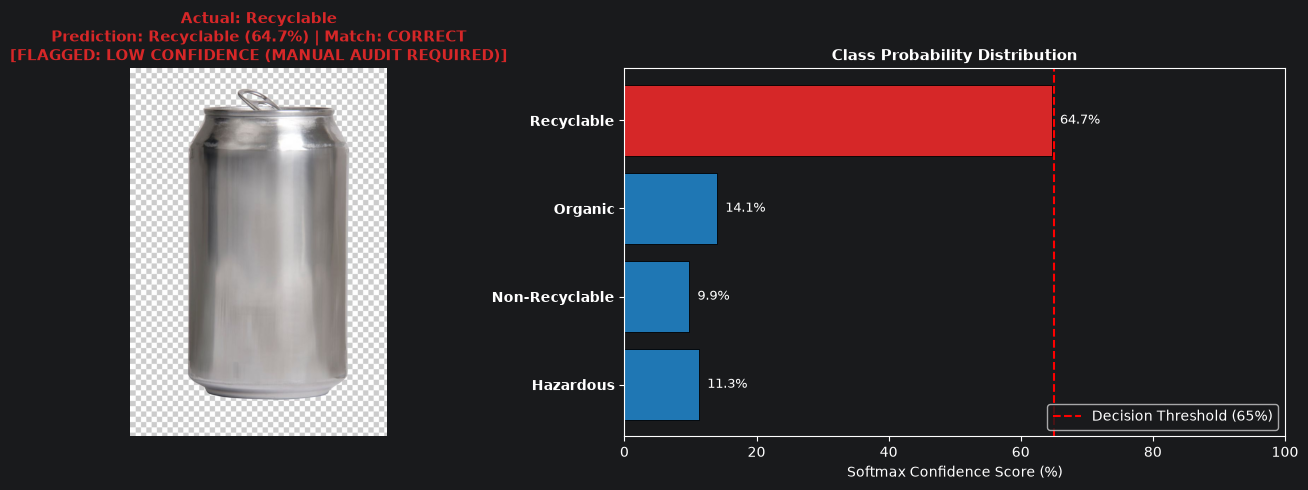


================ Inference Audit: imgbin-beer-recycling-bottle-beverage-can-waste-container-n16Eb9uEgizMUQNdZ2pyKAidT.jpg ================
  True Label        : Recyclable
  Predicted Label   : Recyclable (64.73%)
  Classification    : SUCCESS
  Operational Status: ROUTED TO HUMAN INSPECTION
---------------------------------------------------------------
  Hazardous       :  11.34%
  Non-Recyclable  :   9.85%
  Organic         :  14.08%
  Recyclable      :  64.73% <--



In [22]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

def predict_waste_item(image_path: str, confidence_threshold: float = 0.65):
    """
    Runs ResNet-18 inference on a single image, compares it against the ground truth,
    displays probability bars, and applies a confidence guardrail.
    """
    path = Path(image_path)
    if not path.exists():
        print(f"Error: File not found at '{image_path}'")
        return

    # 1. Determine Ground Truth from directory structure
    actual_class = "Unknown / Custom Image"
    for parent in path.parents:
        if parent.name in classes:
            actual_class = parent.name
            break

    # 2. Image Preprocessing (IVP Standardization)
    raw_img = Image.open(path).convert("RGB")
    tensor_img = val_test_transforms(raw_img).unsqueeze(0).to(device)

    # 3. Model Inference & Softmax Normalization
    model.eval()
    with torch.no_grad():
        logits = model(tensor_img)
        probabilities = F.softmax(logits, dim=1).squeeze().cpu().numpy()

    top_idx = int(np.argmax(probabilities))
    pred_class = classes[top_idx]
    pred_confidence = probabilities[top_idx]

    # 4. Verification and Guardrail Status
    is_correct = (actual_class == pred_class) if actual_class in classes else None
    is_confident = pred_confidence >= confidence_threshold

    if is_confident:
        status_text = "CONFIDENT PREDICTION"
        status_color = "#2ca02c"  # Green
    else:
        status_text = "FLAGGED: LOW CONFIDENCE (MANUAL AUDIT REQUIRED)"
        status_color = "#d62728"  # Red

    # 5. Dual-Panel Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Left: Image display with True and Predicted classes
    ax1.imshow(raw_img)
    ax1.axis("off")

    match_str = f" | Match: {'CORRECT' if is_correct else 'INCORRECT'}" if is_correct is not None else ""
    ax1.set_title(
        f"Actual: {actual_class}\nPrediction: {pred_class} ({pred_confidence * 100:.1f}%){match_str}\n[{status_text}]",
        fontsize=11,
        fontweight="bold",
        color=status_color
    )

    # Right: Softmax Probability Distribution
    bar_colors = [status_color if c == pred_class else "#1f77b4" for c in classes]
    y_pos = np.arange(len(classes))
    ax2.barh(y_pos, probabilities * 100, color=bar_colors, edgecolor="black", linewidth=0.6)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(classes, fontsize=10, fontweight="bold")
    ax2.axvline(
        x=confidence_threshold * 100,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Decision Threshold ({int(confidence_threshold * 100)}%)"
    )
    ax2.set_xlim(0, 100)
    ax2.set_xlabel("Softmax Confidence Score (%)", fontsize=10)
    ax2.set_title("Class Probability Distribution", fontsize=11, fontweight="bold")
    ax2.legend(loc="lower right")

    for i, prob in enumerate(probabilities):
        ax2.text(prob * 100 + 1.2, i, f"{prob * 100:.1f}%", va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

    # 6. Terminal Summary
    print(f"\n================ Inference Audit: {path.name} ================")
    print(f"  True Label        : {actual_class}")
    print(f"  Predicted Label   : {pred_class} ({pred_confidence * 100:.2f}%)")
    print(f"  Classification    : {'SUCCESS' if is_correct else 'FAILURE/MISCLASSIFIED' if is_correct is not None else 'N/A'}")
    print(f"  Operational Status: {'AUTOMATED ROUTING' if is_confident else 'ROUTED TO HUMAN INSPECTION'}")
    print("---------------------------------------------------------------")
    for cls_name, prob in zip(classes, probabilities):
        tag = " <--" if cls_name == pred_class else ""
        print(f"  {cls_name:<16}: {prob * 100:6.2f}%{tag}")
    print("===============================================================\n")


# --- Test Execution ---
sample_images = list(DATA_DIR.rglob("*.jpg")) + list(DATA_DIR.rglob("*.png"))
if sample_images:
    test_sample = str(np.random.choice(sample_images))
    print(f"Evaluating: {test_sample}")
    predict_waste_item(test_sample, confidence_threshold=0.65)